In [3]:
# YOLO 및 Roboflow 사용하기 위한 설치 명령문
!pip install -q ultralytics roboflow

In [4]:
import cv2      # OpenCV 라이브러리
import matplotlib.pyplot as plt      # 이미지 출력에 사용

from ultralytics import YOLO      # YOLO 모델 (딥러닝)
from roboflow import Roboflow     # Roboflow 서비스 활용
from pathlib import Path          # 다운로드 받은 파일 관리 목적

# RoboFlow :: 코딩X 이미지/영상 처리와 관련한 AI 모델 구축하는 브라우저 서비스

In [5]:
# 다른 사용자 AI 모델의 "데이터셋 다운로드" 하는 데에 Roboflow 사용

# RoboFlow 프로젝트 접근 준비
rf = Roboflow(api_key="aLiunxQwG6LnaqKvQr9S")
project = rf.workspace("ss-workspace-3c2gu").project("dog-and-cat-eu2ol-sfk4u")

# 데이터셋 다운로드(1번 버전)
dataset = project.version(1).download('yolov11')

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov11 in progress : 94.0%
Version export complete for yolov11 format



Extracting Dataset Version Zip to dog-and-cat-1 in yolov11:: 100%|██████████| 558/558 [00:00<00:00, 7117.27it/s]


In [7]:
# YOLO 모델 불러오기
model = YOLO('yolo11n.pt')

# 데이터셋으로 추가 학습 (학습용 데이터 파일, 학습 반복 횟수, 이미지 크기(통일))
model.train(
    data = dataset.location + '/data.yaml',
    epochs = 10,
    imgsz = 256
)

New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dog-and-cat-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, mome

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79a234f5de50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [8]:
# 성능이 가장 좋았던 모델 가져오기

# 하나의 YOLO 모델에 대해 10번 학습
# 1 ~ 10번 Epoch의 mAP50(성능) 값들 중, 가장 높은 값을 가지는 상태의 모델을 가져오기
Model_Path = model.trainer.best
train_model =YOLO(str(Model_Path))

In [25]:
# 객체(물체) 검출/탐지 진행

# 데이터셋에 있는 테스트 이미지 가져오기 (TestSet, .jpg 형식)
test_images = list(
    Path(dataset.location + '/test/images').glob('*.jpg')
)

# 테스트용 이미지 하나 선택
Image = test_images[17]

# 객체 검출 진행
results = train_model(
    str(Image),
    conf = 0.25
)

rs = results[0]


image 1/1 /content/dog-and-cat-1/test/images/415_jpg.rf.94c30d446dc7d1749ef526af6a07f6ba.jpg: 256x256 1 cat, 1 dog, 9.7ms
Speed: 0.9ms preprocess, 9.7ms inference, 1.4ms postprocess per image at shape (1, 3, 256, 256)


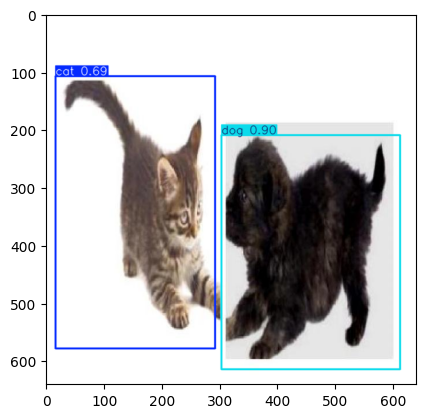

In [26]:
# 객체 검출 결과 확인

# 검출된 물체에 있어 표시한 이미지 생성
rs_img = rs.plot()

rs_rgb = cv2.cvtColor(
    rs_img,
    cv2.COLOR_BGR2RGB
)
plt.imshow(rs_rgb)
plt.show()